# Keller-Segel Logistic Model  

Are there precise numerical phase transitions between different behaviors in the Keller-Segel model for chemotaxis? When analyzing the evolution of densities over time and different values for chemotactic sensitivity, one distinct transition appears between diffusion and aggregation.

## Setup  

When building the simulation for the Keller-Segel model, I realized that the base model experiences blowup in a discrete grid, as the base equations place no limit on density at a point. Because of this, I added a logistic growth term in the model to prevent numerical blowup. With this term, the model becomes as follows:  

$$\frac{\partial u}{\partial t} = D_u\nabla^2u - \chi \nabla \cdot (u \nabla v) + ru(\frac{K-u}{K})$$
$$\frac{\partial v}{\partial t} = D_v\nabla^2v - \alpha v + \beta u $$

The constants used when generating data were:
* DT = 0.1
* N = 256
* DU = 0.2
* DV = 1
* ALPHA = 0.1
* BETA = 1
* R = 0.1
* CAPACITY = 2  

Along with these constants, the density and chemoattractant fields began with a random uniform distribution between 0.9 and 1.1. I used seed 4 for numpy rng to preserve consistency. When generating data, I varied the chemotactic sensitivity to find transitions, keeping everything else (all shown above) constant. Some of the values (DT, N, R, and CAPACITY) were kept constant for stability and efficiency. 

## Phase Transition Between Diffusion and Aggregation
When varying chemotactic sensitivity in this model, two distinct behaviors emerge. Below a critical sensitivity threshold, diffusion suppresses chemotaxis and the density field becomes flat. Above it, chemotaxis overcomes the diffusion, causing cells to aggregate into patterns of higher density.

In [171]:
import numpy as np
import matplotlib.pyplot as plt

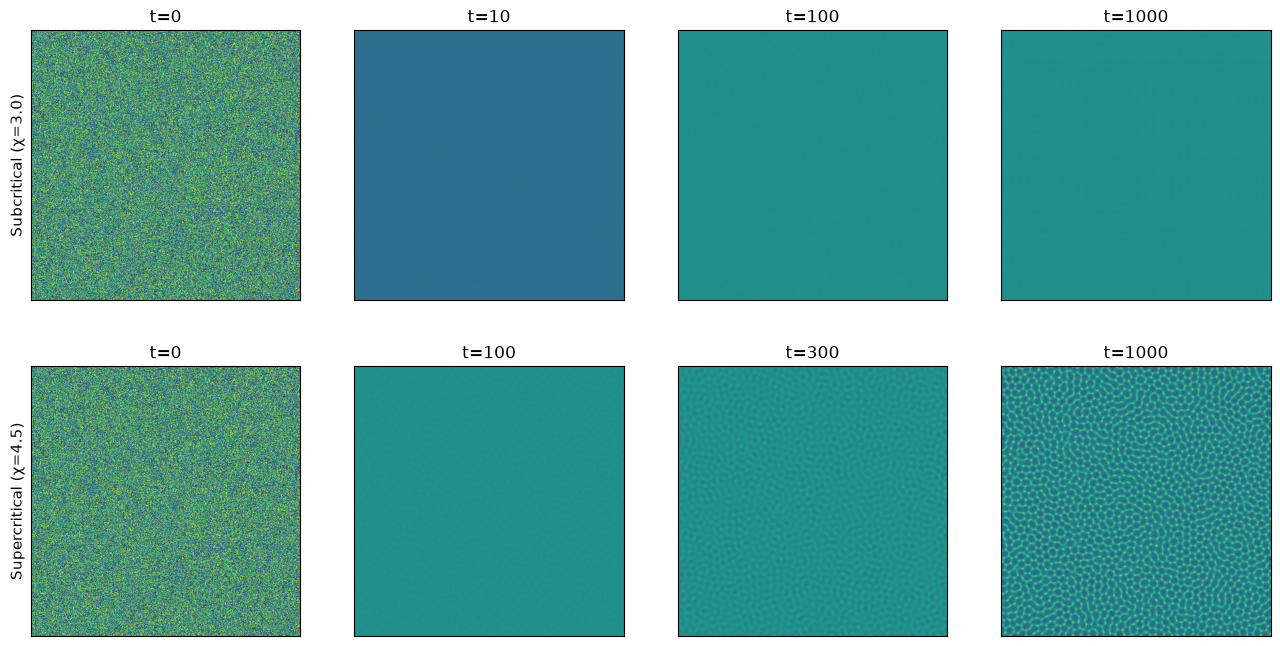

In [173]:
filepath1 = "C:/Users/zekem/Documents/keller-segel-phase-transitions/data/runs/keller_segel_logistic/high_resolution_snapshots/chi=3.npz"
filepath2 = "C:/Users/zekem/Documents/keller-segel-phase-transitions/data/runs/keller_segel_logistic/high_resolution_snapshots/chi=4.5.npz"
with np.load(filepath1, allow_pickle=True) as data:
    step1 = data['step']
    u1 = data['u']
    v1 = data['v']
with np.load(filepath2, allow_pickle=True) as data:
    step2 = data['step']
    u2 = data['u']
    v2 = data['v']

images = [u1[0].astype(float), u1[1].astype(float), u1[10].astype(float), u1[100].astype(float), u2[0].astype(float), u2[10].astype(float), u2[30].astype(float), u2[100].astype(float)]
clims = [(0.9, 1.1), (0, 4), (0, 4), (0, 4), (0.9, 1.1), (0, 4), (0, 4), (0, 4)]
row_labels = ['Subcritical (χ=3.0)', 'Supercritical (χ=4.5)']
sup_col_labels = ["t=0", "t=100", "t=300", "t=1000"]
sub_col_labels = ["t=0", "t=10", "t=100", "t=1000"]

fig, axes = plt.subplots(nrows=2, ncols=4, figsize=(16, 8))
for i, ax in enumerate(axes.ravel()):
    ax.imshow(images[i], cmap='viridis', clim=clims[i])
    ax.set_xticks([])
    ax.set_yticks([])
for i, row in enumerate(axes):
    axes[i,0].set_ylabel(row_labels[i], fontsize=11)
for i, col in enumerate(sup_col_labels):
    axes[1, i].set_title(sup_col_labels[i])
for i, col in enumerate(sub_col_labels):
    axes[0, i].set_title(sub_col_labels[i])

The graphs above show the density field for both subcritical and supercritical sensitivity values at different points in their development. I chose different t values for the middle graphs to better illustrate the different developments of the two regimes. On the top, the subcritical simulation first diffuses rapidly before growing at every point slightly over time until nearing the carrying capacity. On the bottom, the supercritical regime first diffuses, but slowly starts to aggregate until settling at the fully aggregated state seen at t=1000. This stark difference in behavior implies the existence of some distinct phase transition between sensitivity values 3 and 4.5.

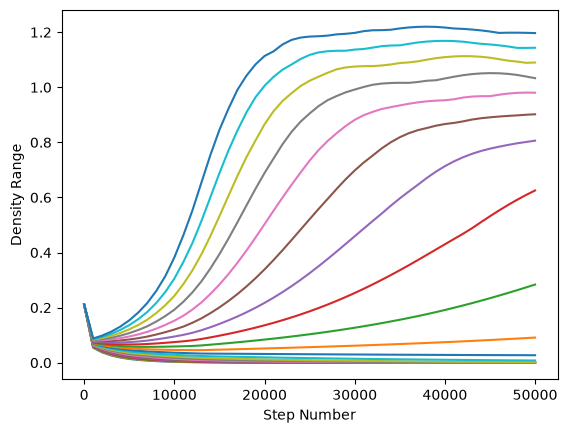

In [ ]:
num_files = 21
num_points = 51
num_steps = 50000
steps = np.empty((num_files, num_points), dtype=np.float32)
us = np.empty((num_files, num_points, 256, 256), dtype=np.float32)
vs = np.empty((num_files, num_points, 256, 256), dtype=np.float32)

idx = 0
chi_values = np.round(np.linspace(4.00, 4.20, 21), decimals=2)
for i in chi_values:
    filepath = "C:/Users/zekem/Documents/keller-segel-phase-transitions/data/runs/keller_segel_logistic/sensitivity_sweep/chi="+str(i)+"_steps="+str(num_steps)+".npz"
    with np.load(filepath, allow_pickle=True) as data:
        steps[idx] = data['step']
        us[idx] = data['u']
        vs[idx] = data['v']
    idx += 1

for i in range(num_files):
    x = np.linspace(0, 50000, num_points)
    density_range = np.empty((steps[i].shape))
    for j in range(len(steps[i])):
        density_range[j] = np.max(us[i, j]) - np.min(us[i, j])
    plt.xlabel("Step Number")
    plt.ylabel("Density Range")
    plt.plot(x, density_range, label="χ="+str(chi_values[i]))

The graph above shows the range of density over time for simulations run between sensitivity 4.0 and 4.2 in increments of 0.01. Density range increases over time in regimes in which the system aggregates, while it flattens to 0 in diffusive setups. As seen in the graph, there is a transition somewhere around sensitivity 4.1 (the blue line at the bottom just above the others). To better identify this transition, I ran longer simulations up to step 200000 for sensitivity values 4.10, 4.1005, 4.101, and 4.1015.

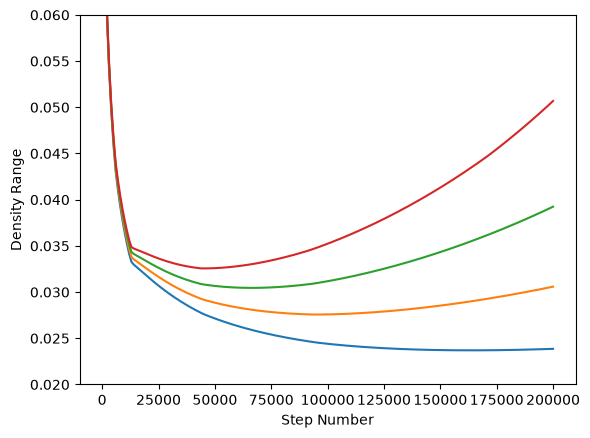

In [180]:
num_files = 4
num_points = 201
num_steps = 200000
steps = np.empty((num_files, num_points), dtype=np.float32)
us = np.empty((num_files, num_points, 256, 256), dtype=np.float32)
vs = np.empty((num_files, num_points, 256, 256), dtype=np.float32)

idx = 0
chi_values = np.round(np.linspace(4.1, 4.1015, 4), decimals=4)
for i in chi_values:
    filepath = "C:/Users/zekem/Documents/keller-segel-phase-transitions/data/runs/keller_segel_logistic/sensitivity_sweep/chi="+str(i)+"_steps="+str(num_steps)+".npz"
    with np.load(filepath, allow_pickle=True) as data:
        steps[idx] = data['step']
        us[idx] = data['u']
        vs[idx] = data['v']
    idx += 1

for i in range(num_files):
    x = np.linspace(0, 200000, num_points)
    density_range = np.empty((steps[i].shape))
    for j in range(len(steps[i])):
        density_range[j] = np.max(us[i, j]) - np.min(us[i, j])
    plt.ylim(0.02, 0.06)
    plt.xlabel("Step Number")
    plt.ylabel("Density Range")
    plt.plot(x, density_range, label="χ="+str(chi_values[i]))

The figure above shows this run of 200000 steps with sensitivities between 4.10 and 4.1015. The sensitivities match the height of the lines, with the blue line at the bottom representing sensitivity 4.10. As you can see, the top three lines begin to increase, the middle two only increasing after the 50000th step, which we couldn't see past in the last run. The bottom line also appears to increase slightly near step 200000, suggesting that it might also aggregate eventually. This highlights the difficulty in judging where the phase transition occurs, as the time to aggregate increases asymptotically as sensitivity approaches the critical value (as shown in the next figure). Another feature of this graph that is worth noting is the sharp increase of the slope of density range over time around step 12000. This likely marks the transition between linear and nonlinear dynamics, as early rapid diffusion to resolve the random initial condition masks the chemotaxis. The chemotaxis term only begins to dominate after this point.

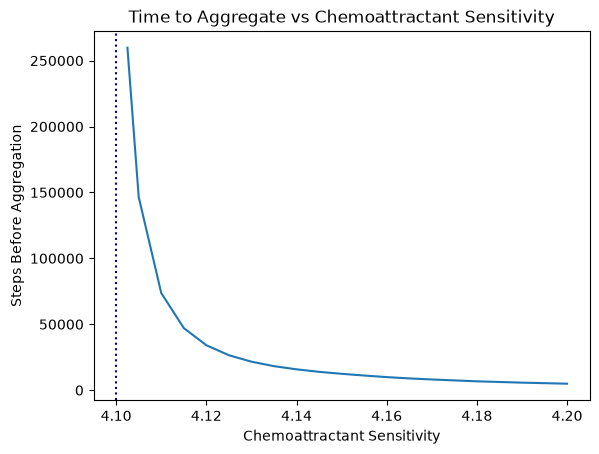

In [135]:
chi_values = np.round(np.linspace(4.105, 4.2, 20), decimals=5)
filepath = "C:/Users/zekem/Documents/keller-segel-phase-transitions/data/runs/keller_segel_logistic/density_divergence/chi=4.11-4.2_n_vals=19.npz"
with np.load(filepath, allow_pickle=True) as data:
    div_steps = data['div_step']
div_steps = np.insert(div_steps, 0, 146500.0)
chi_values = np.insert(chi_values, 0, 4.1025)
div_steps = np.insert(div_steps, 0, 259800.0)

plt.xlabel("Chemoattractant Sensitivity")
plt.ylabel("Steps Before Aggregation")
plt.title("Time to Aggregate vs Chemoattractant Sensitivity")
plt.axvline(x=4.1, color='navy', linestyle=':')
plt.plot(chi_values, div_steps)
plt.show()

This figure illustrates how difficult it is to determine the exact phase transition between diffusion and aggregation, as the amount of time it takes to see aggregation increases asymptotically as sensitivity approaches the transition. This represents a critical slowing down of the system, meaning the relaxation time of the system diverges when sensitivity approaches the bifurcation point between diffusion and aggregation. I therefore characterize the transition by measuring the density range at a fixed time across a wider sensitivity range, rather than trying to find the exact critical value with longer simulations.

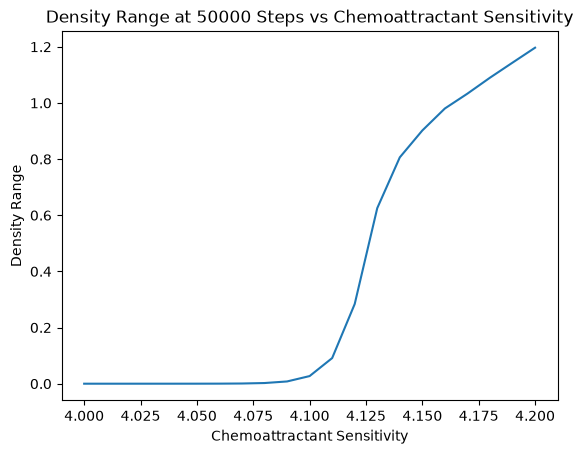

In [167]:
max_density_range = np.empty((num_files))
for i in range(num_files):
    max_density_range[i] = np.max(us[i, num_points - 1]) - np.min(us[i, num_points - 1])
plt.xlabel("Chemoattractant Sensitivity")
plt.ylabel("Density Range")
plt.title("Density Range at 50000 Steps vs Chemoattractant Sensitivity")
plt.plot(chi_values, max_density_range)
plt.show()

The graph above depicts the range of density in each simulation after 50000 steps. Below sensitivity=4.10, density range decays to zero over time as cells diffuse. At sensitivity=4.10, density range begins to grow, marking the onset of aggregation. This value represents my estimate of the critical sensitivity as approximately 4.10.

## Limitations
This chemotaxis model is not without significant limitations. As I previously explained, numerical blowup causes the base model to crash almost immediately. While I added logistic growth to fix this, the system still blows up when run with sensitivity greater than 5.5 or dt above 0.1. This makes it impossible to understand what behavior might look like in higher sensitivity regimes. Along with this, as sensitivity increases, artifacts start to appear in the density field from the spectral methods used for differentiation. Oscillating regions of density appear, originating from high-density points, causing strange visuals and likely leading to inaccurate results. Another limitation that doesn't result from numerical errors is the stability of the logistic term. While it prevents blowup in low-sensitivity regimes, it results in a system where the only possible behaviors result in fixed endpoints. For subcritical regimes, densities homogenize and remain there forever. For supercritical regimes, aggregation occurs, and once densities in aggregated regions reach the carrying capacity, they stabilize and stop moving. This results in the inability for more complex and interesting behaviors to emerge in this model.
## Conclusion
Through the analysis of density over time in many sensitivity regimes, I found that a sharp phase transition exists near a chemotactic sensitivity value of 4.10. At this transition, a critical slowing down is observed when examining the time systems close to the critical value take to aggregate. Because this behavior is consistent with real bifurcations, it indicates that the critical sensitivity value is a bifurcation, rather than a simple smooth crossover.
## Next Steps
Having established a significant phase transition in the keller segel chemotaxis model with this analysis, I aim to characterize more complex behaviors over a higher-dimensional parameter space. Because that is impossible through the logistic growth extension of the model alone, I will be extending the model for further research. I will implement an excitable dynamics field that causes cells to only emit chemoattractant after crossing a specific threshold and be unable to emit more chemoattractant for a certain refractory period after this. This should produce dynamics like traveling waves that more directly model things like slime mold cAMP signaling, enabling richer phase structure and topological analysis in subsequent work.